# Cue accumulation

The cue accumulation task of Bellec et al. (2020, Fig. 3)

Input: 4 populations of 10 Poisson neurons each

- 7 cues, each on the left or the right, one side favoured in each trial
- a fixed delay of 1050 ms
- a decision period in which the network has to report the side with more cues

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from snnrl.tasks import CueAccumulation, sample_batch, sample_trial

In [2]:
BATCH_SIZE = 512
SEED = 0

main_key = jax.random.key(SEED)

In [3]:
task = CueAccumulation()
populations = ["left", "right", "decision", "background"]

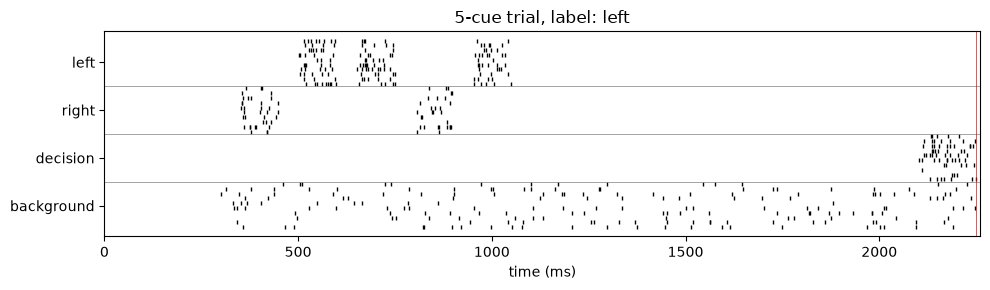

In [4]:
N_CUES = 5

main_key, sample_key = jax.random.split(main_key)

x, label = sample_trial(sample_key, n_cues=N_CUES, task=task)
times, inputs = jnp.nonzero(x) # x.shape = (T, n_in)
label = 'left' if label == 0 else 'right'

fig, ax = plt.subplots(figsize=(10, 3))

ax.plot(times + 1, inputs, "|", color="k", ms=3)
for k in range(1, 4):
    ax.axhline(10 * k - 0.5, color="gray", lw=0.5)
ax.set_yticks([4.5, 14.5, 24.5, 34.5], populations)
ax.axvline(task.trial_length, color="red", lw=0.5)
ax.set_xlim(0, task.trial_length + 10)
ax.set_xlabel("time (ms)")
ax.set_title(f"{N_CUES}-cue trial, label: {label}")
ax.invert_yaxis()
plt.tight_layout()

In [5]:
def validate_trial_structure(key, n_cues, task, batch_size=512):
    
    x, label = sample_batch(key, batch_size, n_cues, task)
    t = np.arange(task.trial_length)

    # Spike counts per population at each time step (0 to 10)
    pop = np.asarray(x).reshape(
        x.shape[0], # batch
        task.trial_length, # T
        4, # populations
        task.n_population # neurons per population
    ).sum(-1) # (batch, T, 4)
    
    start = task.trial_length - (n_cues * task.t_cue_spacing + task.max_delay + task.t_decision)
    onsets = start + np.arange(n_cues) * task.t_cue_spacing + (task.t_cue_spacing - task.t_cue)
    in_cue = ((t[:, None] >= onsets) & (t[:, None] < onsets + task.t_cue)).any(1)
    in_decision = t >= task.trial_length - task.t_decision

    print(f"Validating trial structure for {n_cues} cues:")
    print(f"  - No activity outside cue windows: {(pop[:, ~in_cue, :2] == 0).all()}")
    print(f"  - No activity outside decision window: {(pop[:, ~in_decision, 2] == 0).all()}")
    print(f"  - No activity before the start of the trial: {(pop[:, t < start, 3] == 0).all()}")
    print(f"  - P(right): {float(label.mean()):.2f}")


for n_cues in [1, 3, 5, 7]:
    main_key, batch_key = jax.random.split(main_key)
    validate_trial_structure(batch_key, n_cues, task)

Validating trial structure for 1 cues:
  - No activity outside cue windows: True
  - No activity outside decision window: True
  - No activity before the start of the trial: True
  - P(right): 0.53
Validating trial structure for 3 cues:
  - No activity outside cue windows: True
  - No activity outside decision window: True
  - No activity before the start of the trial: True
  - P(right): 0.47
Validating trial structure for 5 cues:
  - No activity outside cue windows: True
  - No activity outside decision window: True
  - No activity before the start of the trial: True
  - P(right): 0.53
Validating trial structure for 7 cues:
  - No activity outside cue windows: True
  - No activity outside decision window: True
  - No activity before the start of the trial: True
  - P(right): 0.46
